# **Anticipation des retards de livraison - DataCo Smart Supply Chain**
##  Projet AAA (Analyse de données et Apprentissage Automatique) - IMT Atlantique

### Description du projet et du dataset

**Objectif :** Prédire, **au moment où la commande est passée**, si elle risque d'être livrée en retard (`Late_delivery_risk` = 1) à partir de ses caractéristiques : produit, client, région, mode d'expédition, délai annoncé, montant, remise. C'est une tâche de **classification binaire**. On compare plusieurs modèles de classification et on identifie les facteurs qui pèsent le plus sur le retard.

**Enjeu métier.** Le taux de service (livraisons à l'heure) est un indicateur clé en supply chain. Repérer les commandes à risque dès leur création permet d'agir avant la perturbation (changer de transporteur, prévenir le client, prioriser la préparation) plutôt que de la subir.

**Solutions existantes.** Ce dataset est très utilisé (Kaggle, publications académiques) pour la prédiction des retards, la détection de fraude et la prévision des ventes. Plusieurs notebooks publics obtiennent des scores proches de 100 % sur le retard, mais en utilisant des colonnes qui ne sont connues **qu'après la livraison** (`Days for shipping (real)`, `Delivery Status`) : c'est une **fuite de données**, le modèle « lit » la réponse. Notre approche n'utilise que les informations disponibles à la commande : les scores seront plus bas, mais réalistes et utilisables en production.

**Source du dataset.**
- Source d'origine : *DataCo SMART SUPPLY CHAIN FOR BIG DATA ANALYSIS*, Constante F., Silva F., Pereira A. (2019), Mendeley Data - https://data.mendeley.com/datasets/8gx2fvg2k6/5
- Version téléchargée pour ce projet (copie Kaggle du même dataset) : https://www.kaggle.com/datasets/saicharankomati/dataco-supply-chain-dataset

Fichier utilisé : `DataCoSupplyChainDataset.csv` (180 519 lignes, 53 colonnes), compressé en `.zip` et hébergé sur notre dépôt GitHub.

## 1. Imports des bibliothèques

Import de toutes le bibliothèques. Versions utilisées (Python 3.13.15) : pandas, numpy, matplotlib, seaborn, scikit-learn, plotly.
Sur Google Colab, tout est déjà installé. En local, si besoin : `pip install pandas numpy matplotlib seaborn scikit-learn plotly`.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px            # carte interactive (pip install plotly si absent)
from pandas.plotting import scatter_matrix

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | seaborn 0.13.2


## 2. Accès aux données du GitHub (CSV format zip hébergé sur GitHub)
Le dataset est hébergé (zippé) sur notre dépôt GitHub public : `data/raw/DataCoSupplyChainDataset.zip`.
pandas lit directement le `.zip` depuis l'URL (décompression automatique), aucune manipulation n'est nécessaire, que ce soit sur Colab ou en local.
Si l'URL n'est pas accessible (pas de connexion), le code bascule sur la copie locale du dépôt cloné.
L'encodage `latin1` est nécessaire : le fichier contient des caractères accentués qui ne sont pas en UTF-8.


In [38]:
URL_GITHUB = "https://github.com/Nogarrr/Project-Supply-Chain/raw/refs/heads/master/data/raw/DataCoSupplyChainDataset.zip"
CHEMIN_LOCAL = "../data/raw/DataCoSupplyChainDataset.zip"   # si le notebook est dans le dossier notebook/ du dépôt

try:
    df = pd.read_csv(URL_GITHUB, encoding="latin1")
    print("Données chargées depuis GitHub")
except Exception as e:
    print("GitHub inaccessible (", type(e).__name__, ") -> lecture de la copie locale")
    df = pd.read_csv(CHEMIN_LOCAL, encoding="latin1")

df.head()

Données chargées depuis GitHub


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


## 3. Analyse exploratoire des données (EDA)

### 3.1. Métadonnées : nombre d'instances, de variables, types

In [39]:
print("Nombre d'instances :", df.shape[0])
print("Nombre de variables :", df.shape[1])
print()
print(df.dtypes.value_counts())

Nombre d'instances : 180519
Nombre de variables : 53

str        24
float64    15
int64      14
Name: count, dtype: int64


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

**Observations** Le dataset contient 180 519 lignes et 53 colonnes

- On a des variables **numériques** (prix, quantités, délais, remises, identifiants) et **catégorielles** (mode d'expédition, marché, région, segment client, catégorie produit…).
- Plusieurs colonnes sont des **identifiants** (`Order Id`, `Customer Id`, `Product Card Id`…) : codées en nombres, elles n'ont aucun sens quantitatif.
- Plusieurs colonnes sont des **données personnelles** (`Customer Email`, `Customer Password`, noms, adresse) : sans intérêt prédictif, elles ne seront pas utilisées
- Les **dates** (`order date (DateOrders)`, `shipping date (DateOrders)`) sont stockées en texte.
- La **cible** `Late_delivery_risk` est un entier sous forme booléenne 0/1 (1 = livraison en retard).

### 3.2. Valeurs manquantes

In [41]:
manquants = df.isnull().sum() #compte le nombre de valeurs manquantes par colonne
manquants = manquants[manquants > 0].sort_values(ascending=False) #filtre les colonnes avec des valeurs manquantes
pd.DataFrame({"nb_manquants": manquants, "pct": (manquants/ len(df) * 100).round(2)})

,nb_manquants,pct
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


**Observations** Seulement 4 colonnes ont des valeurs manquantes :
*  `Product Description` : 100 % vide, la colonne ne contient aucune information pertinente ;
* `Order Zipcode` : 155679 valeurs manquantes (≈ 86 %)** ;
* `Customer Lname` 8 et `Customer Zipcode` 3 : quelques lignes seulement.

**Stratégies possibles** : supprimer la colonne, supprimer les lignes concernées, imputer (valeur la plus fréquente, médiane…), ou ajouter un indicateur « valeur manquante ».

**Choix et stratégie choisie.**
*  On supprime les colonnes `Product Description` (vide) et `Order Zipcode` (86 % de manquants : une imputation inventerait l'essentiel des valeurs ; de plus, un code postal est un identifiant géographique déjà couvert par `Order City`, `Order State`, `Order Region`).
*  On supprime les 11 lignes incomplètes sur `Customer Lname` / `Customer Zipcode` : elles représentent moins de 0,01 % des données, et ces colonnes seront  exclues 

In [42]:
#Suppression des colonnes inutiles et des lignes avec des valeurs manquantes dans les colonnes "Customer Lname" et "Customer Zipcode"
df = df.drop(columns=["Product Description", "Order Zipcode"])
df = df.dropna(subset=["Customer Lname", "Customer Zipcode"])
print(df.shape)
print("Valeurs manquantes restantes :", df.isnull().sum().sum())

(180508, 51)
Valeurs manquantes restantes : 0


**Observations**: Après nettoyage : 180 508 lignes, 51 colonnes, plus aucune valeur manquante.

### 3.3. Granularité des données : une ligne = un article commandé

In [51]:
print("Lignes :", len(df), "| Commandes distinctes :", df["Order Id"].nunique())

# La cible est-elle la même pour tous les articles d'une même commande ?
verif = df.groupby("Order Id")["Late_delivery_risk"].nunique()
print("Commandes avec une cible incohérente :", (verif > 1).sum())

Lignes : 180508 | Commandes distinctes : 65741
Commandes avec une cible incohérente : 0


**Observations**: On a 180 508 lignes pour 65 741 commandes (≈ 2,7~3 articles par commande) : chaque ligne est un article d'une commande, pas une commande.
La cible est identique pour tous les articles d'une même commande (0 commande incohérente), ce qui est logique : c'est la commande entière qui est livrée en retard ou non.

**Conséquence pour la modélisation**: On garde la granularité article (plus de données, et les caractéristiques produit diffèrent d'une ligne à l'autre). Mais les articles d'une même commande partagent la même cible et les mêmes informations client/expédition : si une commande se retrouve à la fois dans le train et dans le test, le score sera légèrement optimiste. Pour l'éviter, le découpage train/validation/test se fera par commande (`GroupShuffleSplit` sur `Order Id`).

### 3.4. Distributions, valeurs aberrantes et mise à l'échelle

#### 3.4.1.Distributions

In [52]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180508.0,3.497673,1.623743,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180508.0,2.931837,1.374457,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180508.0,21.971563,104.433860,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180508.0,183.101751,120.041578,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180508.0,0.548297,0.497663,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180508.0,31.849270,15.637996,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180508.0,6690.778857,4162.304984,1.000000,3258.000000,6456.000000,9779.000000,20757.000000
Customer Zipcode,180508.0,35920.246698,37542.214613,603.000000,725.000000,19380.000000,78202.500000,99205.000000
Department Id,180508.0,5.443454,1.629175,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180508.0,29.719858,9.813737,-33.937553,18.265432,33.144863,39.279617,48.781933


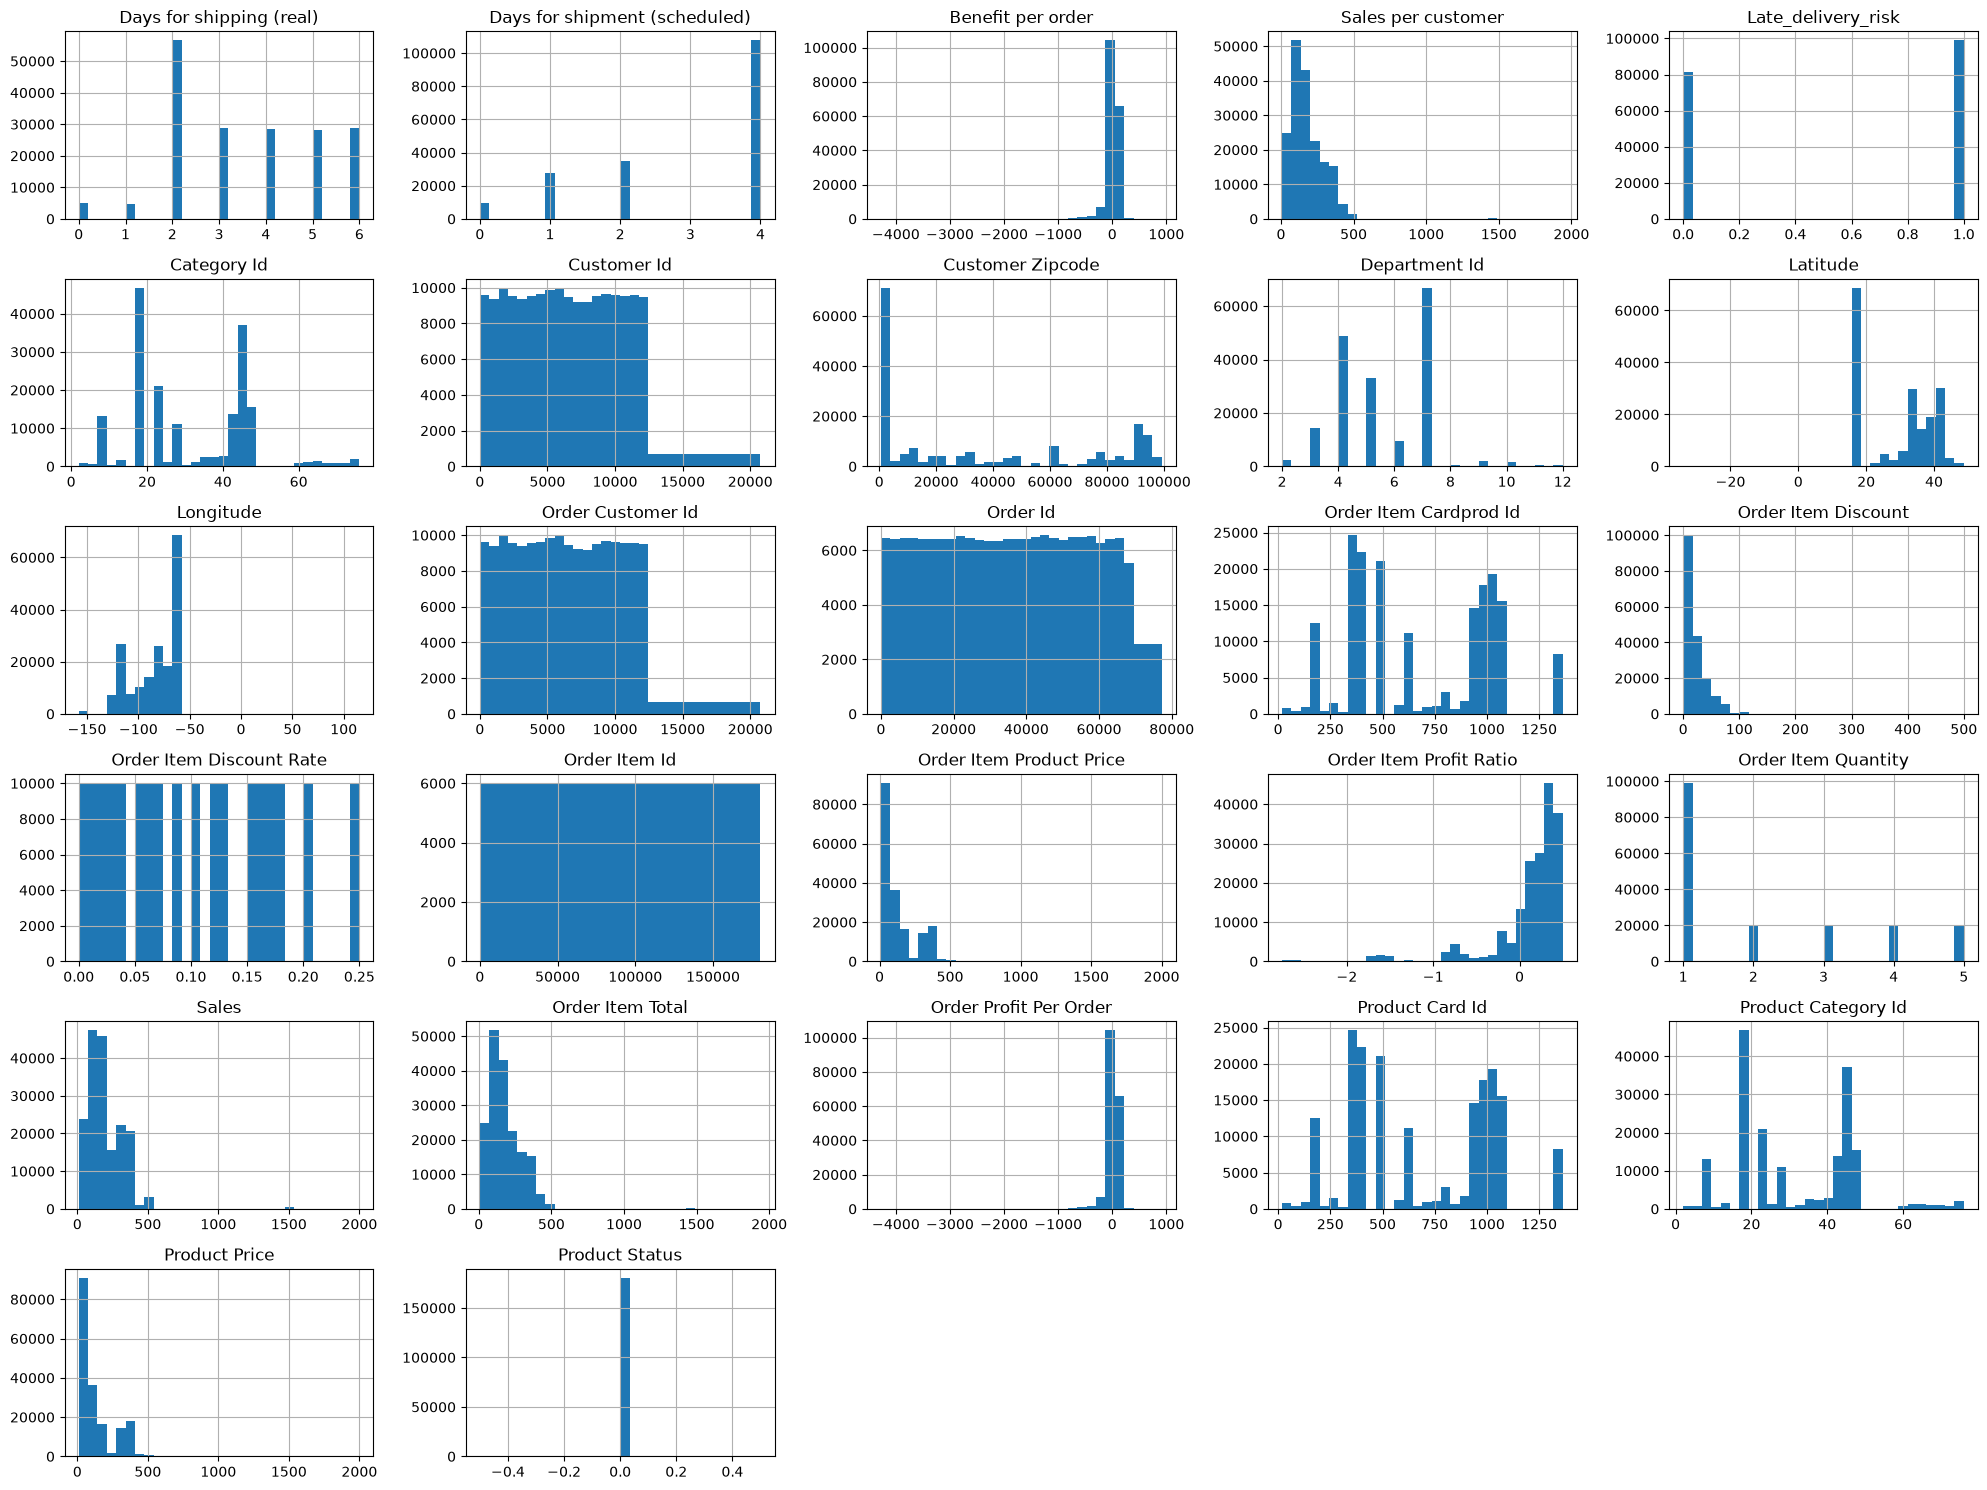

In [53]:
df.hist(bins=30, figsize=(20, 15))
plt.tight_layout()
plt.show()

**Observations**
- `Days for shipment (scheduled)` ne prend que quelques valeurs entières entre 0 et 4 : il dépend directement du mode d'expédition.
- `Order Item Quantity` va de 1 à 5, avec une médiane à 1 : la plupart des lignes sont un seul article.
- `Sales`, `Order Item Product Price`, `Sales per customer` sont asymétriques à droite : beaucoup de petits montants, quelques commandes très chères (jusqu'à ~2 000).
- `Benefit per order` a une longue queue négative (minimum −4 275) : certaines commandes sont vendues à perte.
- `Order Item Discount Rate` est compris entre 0 et 0,25.
- `Product Status` vaut toujours 0 (écart-type nul) : variable constante, sans information.
- Plusieurs paires de colonnes ont exactement les mêmes statistiques (`Product Price` / `Order Item Product Price`, `Sales per customer` / `Order Item Total`, `Benefit per order` / `Order Profit Per Order`, `Category Id` / `Product Category Id`) : ce sont des doublons, vérifiés en 3.6.
- Les histogrammes des identifiants (`Order Id`, `Customer Id`…) n'ont pas de sens : ce sont des numéros.

#### 3.4.2. Valeurs aberrantes (méthode de l'écart interquartile, IQR)

Une valeur est considérée comme aberrante si elle sort de l'intervalle *__[Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]__*.

Sales per customer : [-110.15 ; 461.93] -> 1943 valeurs aberrantes (1.1 %)
Order Item Product Price : [-174.99 ; 424.98] -> 2045 valeurs aberrantes (1.1 %)
Benefit per order : [-79.70 ; 151.50] -> 18938 valeurs aberrantes (10.5 %)
Order Item Quantity : [-2.00 ; 6.00] -> 0 valeurs aberrantes (0.0 %)


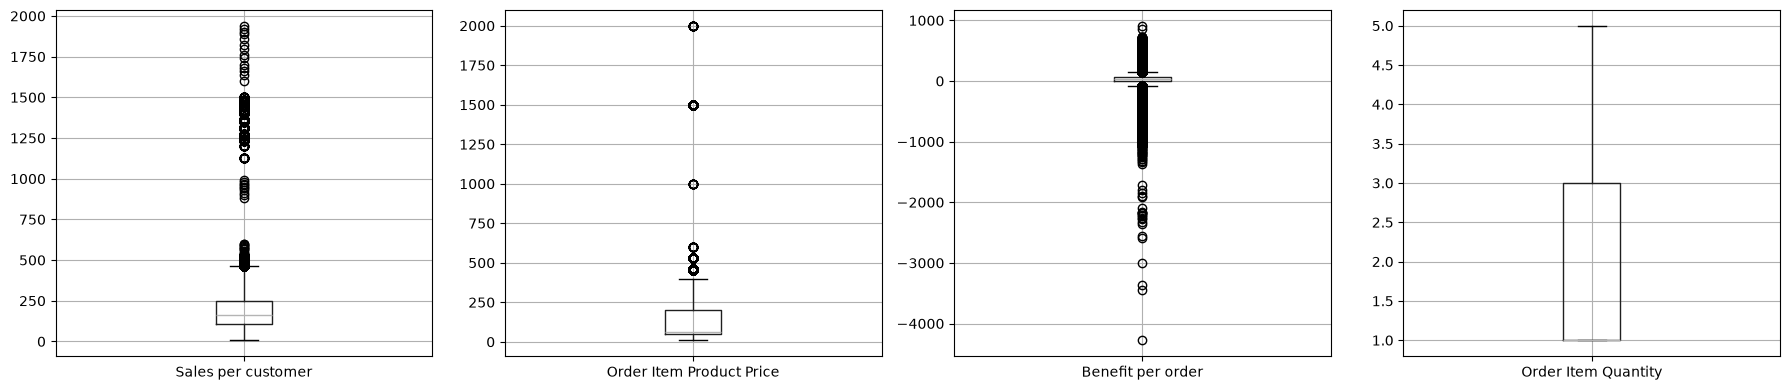

In [54]:
def bornes_iqr(colonne):
    q1 = df[colonne].quantile(0.25)
    q3 = df[colonne].quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

cols_iqr = ["Sales per customer", "Order Item Product Price", "Benefit per order", "Order Item Quantity"]
for col in cols_iqr:
    basse, haute = bornes_iqr(col)
    nb = ((df[col] < basse) | (df[col] > haute)).sum()
    print(f"{col} : [{basse:.2f} ; {haute:.2f}] -> {nb} valeurs aberrantes ({nb / len(df) * 100:.1f} %)")

fig, axes = plt.subplots(1, len(cols_iqr), figsize=(18, 4))
for ax, col in zip(axes, cols_iqr):
    df.boxplot(column=col, ax=ax)
plt.tight_layout()
plt.show()

**Observations**
* `Sales per customer` : 1,1 % de valeurs au-dessus de 461,93 (la borne basse négative n'a pas de sens pour un montant). Ce sont des commandes de montant élevé, cohérentes avec les produits les plus chers : des valeurs réelles, pas des erreurs.
* `Order Item Product Price` : les valeurs hautes correspondent aux produits les plus chers du catalogue (jusqu'à 2000 environ) : valeurs réelles.
* `Benefit per order` : 10,5 % de valeurs hors bornes, avec un minimum à −4 274,98. La distribution est très étalée, la règle 1,5 × IQR signale donc beaucoup de points ; les pertes correspondent à des ventes à perte ou fortement remisées.
* `Order Item Quantity` : aucune valeur aberrante (entiers de 1 à 5).

**Stratégies possibles** : supprimer les lignes, plafonner les valeurs aux bornes, appliquer une transformation (log), ou garder les valeurs.

**Stratégie choisie**: On garde toutes les valeurs. Elles sont plausibles du point de vue métier, supprimer jusqu'à 10 % des lignes ferait perdre de l'information, et le log n'est pas applicable aux bénéfices négatifs. Les modèles à base d'arbres sont peu sensibles aux valeurs extrêmes, et pour les modèles basés sur les distances l'effet sera atténué par la standardisation. Enfin, `Benefit per order` sera exclue de la modélisation (le bénéfice réel n'est connu qu'après la livraison, voir 3.6), la question de ses valeurs aberrantes ne se pose donc plus pour les modèles.

#### 3.4.3. Mise à l'échelle

In [55]:
num_cols = ["Order Item Product Price", "Order Item Quantity",
            "Order Item Discount Rate", "Sales", "Days for shipment (scheduled)"]
df[num_cols].describe().loc[["mean", "std", "min", "max"]]

,Order Item Product Price,Order Item Quantity,Order Item Discount Rate,Sales,Days for shipment (scheduled)
mean,141.222139,2.127706,0.101668,203.765496,2.931837
std,139.726960,1.453469,0.070416,132.270788,1.374457
min,9.990000,1.000000,0.000000,9.990000,0.000000
max,1999.989990,5.000000,0.250000,1999.989990,4.000000


**Observations**: Les variables numériques ont des ordres de grandeur très différents : `Sales` et `Order Item Product Price` vont de 10 à 2 000, alors que `Order Item Discount Rate` reste entre 0 et 0,25 et que `Order Item Quantity` et `Days for shipment (scheduled)` sont de petits entiers. Sans mise à l'échelle, les modèles basés sur des distances ou des coefficients (K-Means, KNN, régression logistique) seraient dominés par les variables de grande amplitude.

**Choix**: On applique un `StandardScaler` (centrage-réduction : moyenne 0, écart-type 1).
- Dans l'EDA, il sert au clustering et à l'ACP.
- Pour la modélisation supervisée, il sera placé dans le pipeline et ajusté uniquement sur le jeu d'entraînement, pour ne pas faire fuiter d'information du test.
- Les arbres de décision et les forêts aléatoires n'en ont pas besoin (insensibles à l'échelle), mais il ne les pénalise pas : on garde un seul prétraitement commun à tous les modèles.

In [56]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[num_cols])

# Vérification : moyenne ~0, écart-type ~1
pd.DataFrame(X_scaled, columns=num_cols).describe().loc[["mean", "std"]].round(3)

,Order Item Product Price,Order Item Quantity,Order Item Discount Rate,Sales,Days for shipment (scheduled)
mean,-0.0,0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


### 3.5. Étude de la variable cible : `Late_delivery_risk`

                    effectif    pct
Late_delivery_risk                 
1                      98972  54.83
0                      81536  45.17


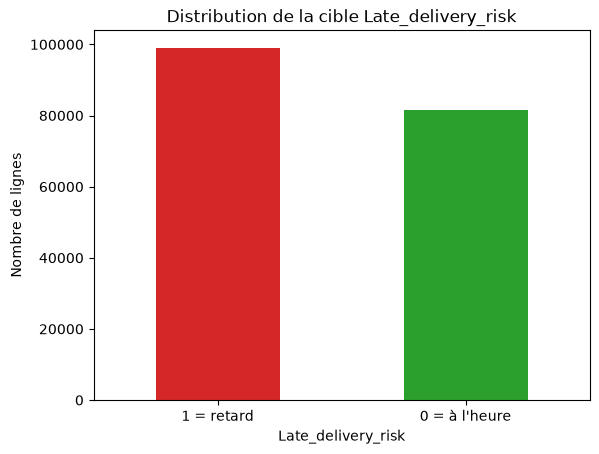

In [57]:
effectifs = df["Late_delivery_risk"].value_counts()
proportions = df["Late_delivery_risk"].value_counts(normalize=True) * 100
print(pd.DataFrame({"effectif": effectifs, "pct": proportions.round(2)}))

effectifs.plot(kind="bar", color=["tab:red", "tab:green"])
plt.xticks([0, 1], ["1 = retard", "0 = à l'heure"], rotation=0)
plt.ylabel("Nombre de lignes")
plt.title("Distribution de la cible Late_delivery_risk")
plt.show()

In [44]:
df["Late_delivery_risk"].value_counts() #compte le nombre de valeurs uniques dans la colonne "Late_delivery_risk"
df["Late_delivery_risk"].value_counts(normalize=True) #affiche le pourcentage de valeurs uniques dans la colonne "Late_delivery_risk"

Late_delivery_risk
1    0.548297
0    0.451703
Name: proportion, dtype: float64

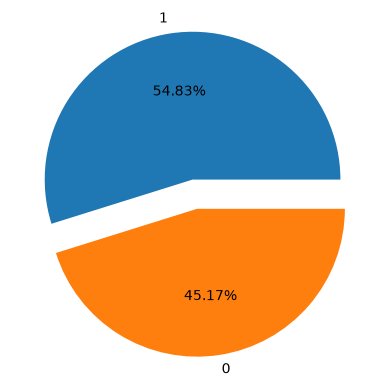

In [45]:
Late_delivery_risk = df["Late_delivery_risk"].value_counts()
Late_delivery_risk.plot.pie(
    autopct="%0.2f%%",
    explode=[0.1] * len(Late_delivery_risk),
);

**Observations**: 54,8 % des lignes sont en retard (98 972) contre 45,2 % à l'heure (81 536). Le taux de retard est donc très élevé (plus d'une commande sur deux), ce qui confirme l'enjeu du sujet. Le déséquilibre entre les classes est "léger" : on est loin des cas problématiques où la classe minoritaire ne représente que 1 à 10 % des données.

**Choix**
* Pas de rééquilibrage (ni sur-échantillonnage, ni sous-échantillonnage, ni SMOTE) : il n'est pas justifié avec un ratio 55/45 (environ de moitié)
* Découpage stratifié sur la cible, pour garder la même proportion de retards dans le train, la validation et le test.
* Référence à battre: un modèle qui prédit toujours « retard » obtient déjà 54,8 % d'accuracy. On suivra donc aussi la précision, le rappel et le F1-score, et pas seulement l'accuracy.

### 3.6 Variables explicatives : lien avec la cible, corrélations et sélection

#### 3.6.1. Taux de retard selon les principales variables catégorielles

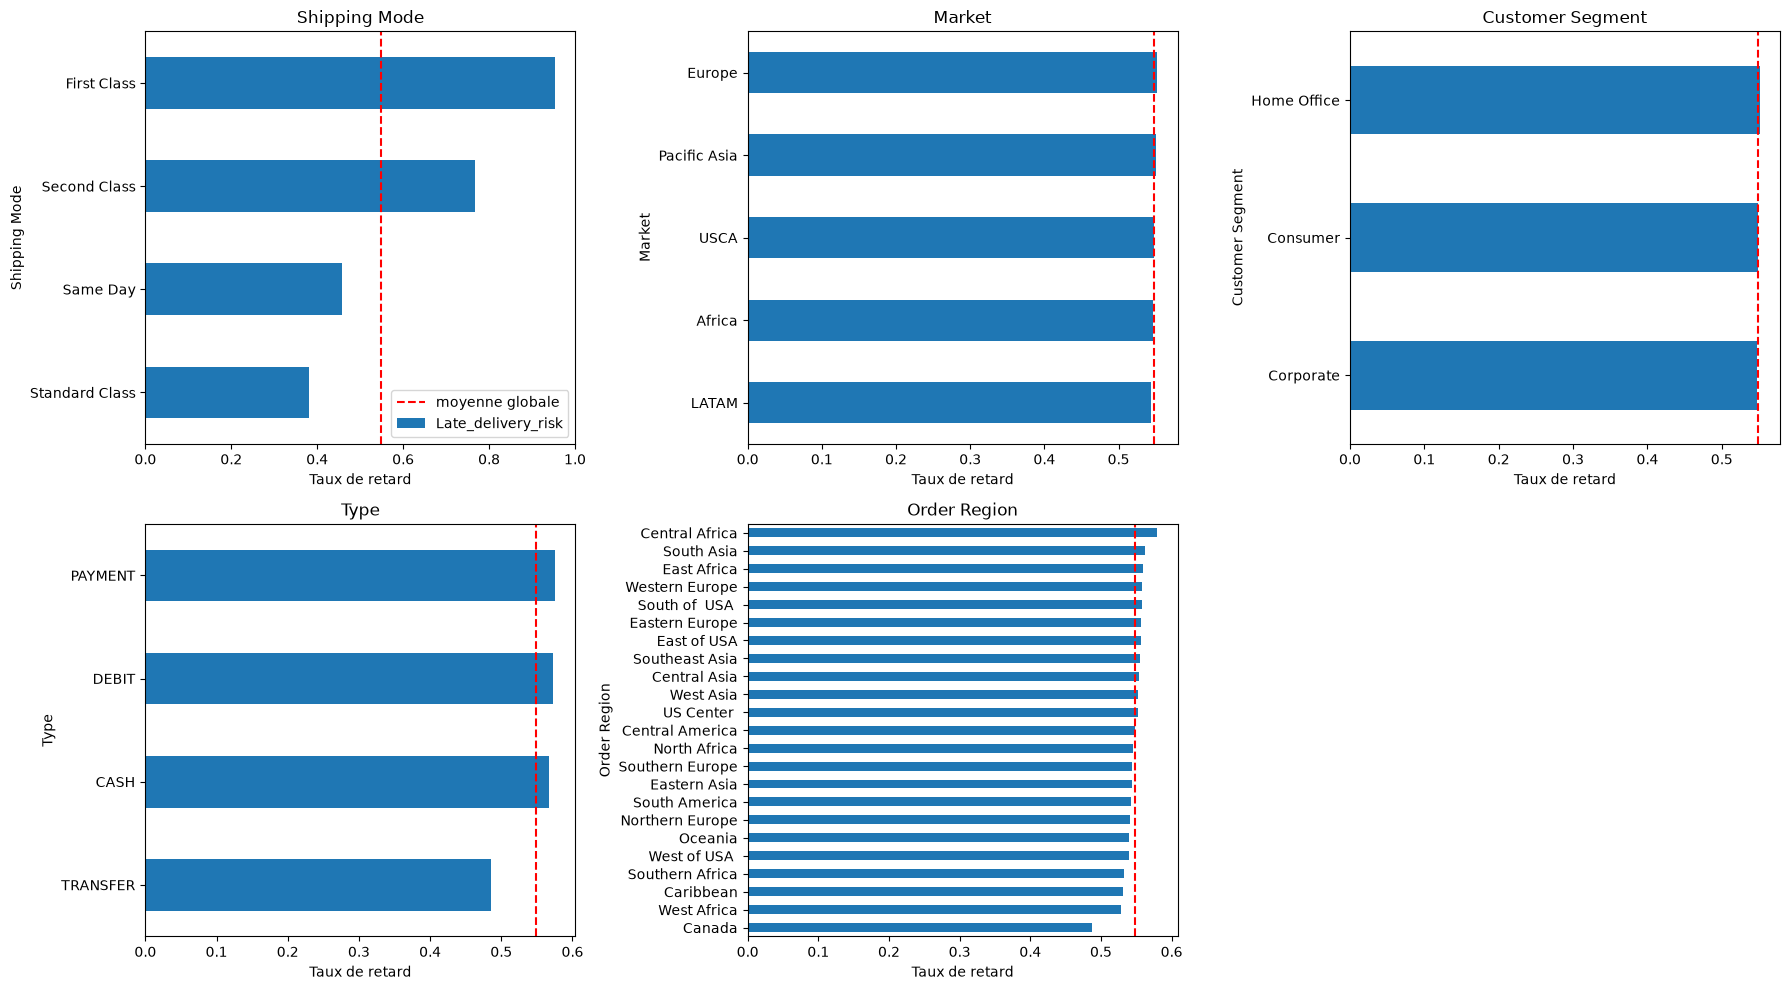

In [58]:
cols_cat_explo = ["Shipping Mode", "Market", "Customer Segment", "Type", "Order Region"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, cols_cat_explo):
    (df.groupby(col)["Late_delivery_risk"].mean().sort_values()
       .plot(kind="barh", ax=ax, color="tab:blue"))
    ax.axvline(df["Late_delivery_risk"].mean(), color="red", linestyle="--", label="moyenne globale")
    ax.set_xlabel("Taux de retard")
    ax.set_title(col)
axes.flat[-1].axis("off")
axes.flat[0].legend()
plt.tight_layout()
plt.show()

In [60]:
# Détail du mode d'expédition : taux de retard et délai annoncé
df.groupby("Shipping Mode").agg(
    nb_lignes=("Late_delivery_risk", "size"),
    taux_retard=("Late_delivery_risk", "mean"),
    delai_annonce_moyen_en_jours=("Days for shipment (scheduled)", "mean"),
).sort_values("taux_retard", ascending=False).round(3)

,nb_lignes,taux_retard,delai_annonce_moyen_en_jours
Shipping Mode,,,
First Class,27812,0.953,1.0
Second Class,35214,0.766,2.0
Same Day,9737,0.457,0.0
Standard Class,107745,0.381,4.0


In [77]:
# Écart de taux de retard entre modalités, pour comparer avec le mode d'expédition
for col in ["Shipping Mode", "Market", "Customer Segment", "Type", "Order Region"]:
    taux = df.groupby(col)["Late_delivery_risk"].mean()
    print(f"{col} : de {taux.min():.1%} à {taux.max():.1%} (écart {100 * (taux.max() - taux.min()):.1f} points)")

Shipping Mode : de 38.1% à 95.3% (écart 57.2 points)
Market : de 54.4% à 55.2% (écart 0.9 points)
Customer Segment : de 54.7% à 55.1% (écart 0.4 points)
Type : de 48.5% à 57.5% (écart 9.0 points)
Order Region : de 48.8% à 58.0% (écart 9.2 points)


**Observations**
* **Mode d'expédition** : c'est de loin la variable la plus discriminante. First Class est en retard dans 95,3 % des cas, Second Class 76,6 %, Same Day 45,7 %, Standard Class 38,1 % : 57 points d'écart entre les extrêmes.
* Le délai promis n'explique pas tout : Same Day (0 jour annoncé) est bien moins en retard que First Class (1 jour annoncé). Ce qui compte, c'est le réalisme de la promesse de chaque mode : First Class promet 1 jour et ne le tient presque jamais.
* `Days for shipment (scheduled)` correspond exactement au mode (Same Day = 0, First = 1, Second = 2, Standard = 4) : les deux colonnes portent la même information. Il faudra s'en souvenir en lisant l'importance des variables.
* Une règle simple « First ou Second Class = retard » donnerait déjà ≈ 69,5 % de bonnes prédictions, contre 54,8 % pour « toujours retard ». C'est une deuxième référence que nos modèles doivent battre.
* **Marché, segment client, type de paiement, région** : écart maximal de **X points** entre modalités, contre 57 points pour le mode d'expédition. Ces variables ont un effet faible, voire nul, sur le retard.

#### 3.6.2. Localisation géographique

*Dans le cours, la carte de la Californie colore chaque district par prix des logements. On fait la même chose avec le taux de retard par localisation en s'aidant des données présentes dans le csv*

In [61]:
print("Positions (Latitude, Longitude) distinctes :", df[["Latitude", "Longitude"]].drop_duplicates().shape[0])
print("Villes clientes distinctes :", df["Customer City"].nunique())

agg = df.groupby(["Latitude", "Longitude"]).agg(
    nb_commandes=("Order Id", "nunique"),
    taux_retard=("Late_delivery_risk", "mean"),
    ville=("Customer City", "first"),
).reset_index()
agg = agg[agg["nb_commandes"] >= 30]   # moins de 30 commandes : taux trop instable pour être interprété

fig = px.scatter_geo(
    agg, lat="Latitude", lon="Longitude",
    size="nb_commandes", size_max=25,
    color="taux_retard", color_continuous_scale="RdYlGn_r",
    range_color=(agg["taux_retard"].quantile(0.05), agg["taux_retard"].quantile(0.95)),
    hover_name="ville",
    hover_data={"nb_commandes": True, "taux_retard": ":.1%", "Latitude": False, "Longitude": False},
    scope="usa", width=1100, height=650,
    title="Taux de retard par localisation (taille = nombre de commandes)",
)
fig.update_traces(marker=dict(line=dict(width=0.5, color="black"), opacity=0.85))
fig.update_geos(landcolor="rgb(250,245,225)", showlakes=True, lakecolor="rgb(170,210,240)",
                subunitcolor="rgb(160,160,160)")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0),
                  coloraxis_colorbar=dict(title="Taux de retard", tickformat=".0%"))
fig.show()

print(agg["taux_retard"].describe().round(3))

Positions (Latitude, Longitude) distinctes : 11831
Villes clientes distinctes : 562


count    338.000
mean       0.547
std        0.088
min        0.295
25%        0.486
50%        0.548
75%        0.608
max        0.792
Name: taux_retard, dtype: float64


**Observations** : Il y a 11 831 positions distinctes pour 562 villes : les coordonnées sont plus fines que la ville. Les clients sont presque tous situés aux États-Unis et à Porto Rico.
Sur les 338 lieux ayant au moins 30 commandes, le taux de retard va de 29,5 % à 79,2 %, avec un écart-type de 8,8 points autour de la moyenne (54,7 %). Cette dispersion est du même ordre que celle que produirait le hasard : pour 30 commandes avec 55 % de retards, l'écart-type attendu par simple fluctuation est d'environ 9 points (√(0,55 × 0,45 / 30)). La carte ne montre donc pas de zone géographique réellement plus en retard.

**Choix** : `Latitude` et `Longitude` sont écartées. L'information géographique est déjà portée par des variables plus simples à interpréter (`Market`, `Order Region`, `Customer State`), et les coordonnées brutes n'ont pas de relation monotone avec le retard.

#### 3.6.3. Corrélations linéaires avec la cible

In [62]:
corr_matrix = df.corr(numeric_only=True)
corr_matrix["Late_delivery_risk"].sort_values(ascending=False)

Late_delivery_risk               1.000000
Days for shipping (real)         0.401418
Customer Zipcode                 0.003166
Category Id                      0.001780
Product Category Id              0.001780
Order Item Cardprod Id           0.001513
Product Card Id                  0.001513
Order Customer Id                0.001512
Customer Id                      0.001512
Department Id                    0.001049
Latitude                         0.000700
Order Item Discount Rate         0.000399
Order Item Quantity             -0.000148
Order Item Discount             -0.000739
Order Id                        -0.001273
Order Item Id                   -0.001357
Longitude                       -0.001953
Order Item Product Price        -0.002160
Product Price                   -0.002160
Order Item Profit Ratio         -0.002319
Sales                           -0.003554
Benefit per order               -0.003729
Order Profit Per Order          -0.003729
Order Item Total                -0

**Combinaison d'attributs**: *comme `rooms_per_household` dans le cours) : on crée l'écart entre délai réel et délai annoncé.*

In [63]:
df["Retard"] = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
df.corr(numeric_only=True)["Late_delivery_risk"].sort_values(ascending=False).head(5)

Late_delivery_risk          1.000000
Retard                      0.777643
Days for shipping (real)    0.401418
Customer Zipcode            0.003166
Category Id                 0.001780
Name: Late_delivery_risk, dtype: float64

**Observations**
* Les deux variables les plus corrélées à la cible sont `Retard` **r = 0,77** et `Days for shipping (real)` **r = 0,40**. Mais ce sont des fuites de données : le délai réel n'est connu qu'une fois le colis livré. Les utiliser reviendrait à donner la réponse au modèle. Elles sont donc exclues.
* Toutes les autres variables numériques ont une corrélation quasi nulle avec la cible (|r| < 0,01) : aucune ne permet, seule et de façon linéaire, de prédire le retard.
* Attention ! la corrélation de Pearson ne mesure que les relations linéaires entre variables numériques. Elle ne voit pas les variables catégorielles comme `Shipping Mode`, ni les relations non linéaires. Une corrélation nulle ne veut donc pas dire « aucun lien » : c'est le rôle des modèles de le vérifier.

#### 3.6.4.Sélection des variables : classement des colonnes en 3 groupes

*Chaque colonne est classée selon une seule question :est-elle connue au moment où la commande est passée ?*

In [65]:
colonnes_connues_a_la_commande = [
    "Type", "Days for shipment (scheduled)", "Category Name", "Customer City",
    "Customer Country", "Customer Segment", "Customer State", "Department Name",
    "Market", "Order City", "Order Country", "Order Region", "Order State",
    "Order Item Discount", "Order Item Discount Rate", "Order Item Product Price",
    "Order Item Quantity", "Sales", "Sales per customer", "Order Item Total",
    "Product Name", "Product Price", "Shipping Mode",
]

colonnes_fuite_apres_livraison = [
    "Days for shipping (real)", "Delivery Status", "Benefit per order",
    "Order Profit Per Order", "Order Item Profit Ratio", "shipping date (DateOrders)",
    "Order Status", "Retard",
]

colonnes_inutiles = [
    "Customer Email", "Customer Fname", "Customer Lname", "Customer Password",
    "Customer Street", "Customer Zipcode", "Customer Id", "Order Customer Id",
    "Order Id", "Order Item Cardprod Id", "Order Item Id", "Product Card Id",
    "Product Image", "Product Status", "Latitude", "Longitude",
    "Category Id", "Department Id", "Product Category Id",
    "order date (DateOrders)",
]

toutes = colonnes_connues_a_la_commande + colonnes_fuite_apres_livraison + colonnes_inutiles + ["Late_delivery_risk"]
print("Colonnes non classées :", set(df.columns) - set(toutes))
print("Colonnes classées mais absentes :", set(toutes) - set(df.columns))

Colonnes non classées : set()
Colonnes classées mais absentes : set()


Les deux colonnes sont vides : toutes les colonnes sont classées.

**Justification des choix**
* **Fuites (connues après la livraison)** : délai réel, statut de livraison, date d'expédition, et tous les indicateurs de bénéfice (le bénéfice final dépend de ce qui s'est passé après la commande). `Order Status` aussi : ses valeurs (`COMPLETE`, `CANCELED`, `PENDING`…) décrivent l'état final de la commande.
* **Inutiles** : identifiants, données personnelles, image produit, `Product Status` (constante), doublons d'identifiants (`Category Id`, `Department Id`, `Product Category Id` répètent les noms de catégorie et de département), coordonnées GPS (voir carte).
* `order date (DateOrders)` : connue à la commande, mais inutilisable brute (texte). On pourra en extraire le jour de la semaine ou le mois dans la partie modélisation améliorée.

In [66]:
# Nombre de modalités des variables catégorielles connues à la commande
cat_connues = [c for c in colonnes_connues_a_la_commande if not pd.api.types.is_numeric_dtype(df[c])]
df[cat_connues].nunique().sort_values(ascending=False)

Order City          3597
Order State         1089
Customer City        562
Order Country        164
Product Name         118
Category Name         50
Customer State        44
Order Region          23
Department Name       11
Market                 5
Type                   4
Shipping Mode          4
Customer Segment       3
Customer Country       2
dtype: int64

In [67]:
SEUIL_MODALITES = 100
cat_cols = [c for c in cat_connues if df[c].nunique() <= SEUIL_MODALITES]
print("Variables catégorielles retenues :", cat_cols)
print("Écartées (trop de modalités) :", [c for c in cat_connues if c not in cat_cols])

Variables catégorielles retenues : ['Type', 'Category Name', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order Region', 'Shipping Mode']
Écartées (trop de modalités) : ['Customer City', 'Order City', 'Order Country', 'Order State', 'Product Name']


**Décision sur les variables catégorielles.** Elles seront encodées en One-Hot (une colonne 0/1 par modalité). Une variable à plusieurs centaines de modalités (`Product Name`, `Order City`, `Customer City`…) créerait des centaines de colonnes très rares, ce qui ralentit l'apprentissage et favorise le surapprentissage. On ne garde donc que les variables à 100 modalités au plus ; l'information écartée reste en partie présente via des variables plus générales (`Category Name` pour le produit, `Order Region` et `Market` pour la géographie).

In [68]:
# Redondances entre variables numériques connues à la commande
paires = [("Product Price", "Order Item Product Price"),
          ("Sales per customer", "Order Item Total")]
for a, b in paires:
    print(f"{a} == {b} :", np.allclose(df[a], df[b]))

# Order Item Total = Sales - Order Item Discount ?
print("Order Item Total == Sales - Order Item Discount :",
      np.allclose(df["Order Item Total"], df["Sales"] - df["Order Item Discount"], atol=0.05))

Product Price == Order Item Product Price : True
Sales per customer == Order Item Total : True
Order Item Total == Sales - Order Item Discount : True


**Choix sur les variables numériques**: `Product Price` est une copie de `Order Item Product Price`, `Sales per customer` une copie de `Order Item Total`, et `Order Item Total` se déduit de `Sales` et de la remise. Garder des colonnes en double n'apporte aucune information et gêne l'interprétation des modèles linéaires (coefficients instables). On garde les 5 variables numériques non redondantes déjà utilisées plus haut : `Order Item Product Price`, `Order Item Quantity`, `Order Item Discount Rate`, `Sales`, `Days for shipment (scheduled)`.

In [69]:
features = num_cols + cat_cols
df_modelisation = df[features + ["Late_delivery_risk"]].copy()

print("Dimensions du jeu de modélisation :", df_modelisation.shape)
print("Numériques :", num_cols)
print("Catégorielles :", cat_cols)

Dimensions du jeu de modélisation : (180508, 15)
Numériques : ['Order Item Product Price', 'Order Item Quantity', 'Order Item Discount Rate', 'Sales', 'Days for shipment (scheduled)']
Catégorielles : ['Type', 'Category Name', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order Region', 'Shipping Mode']


#### 3.6.5. Corrélations entre les variables retenues

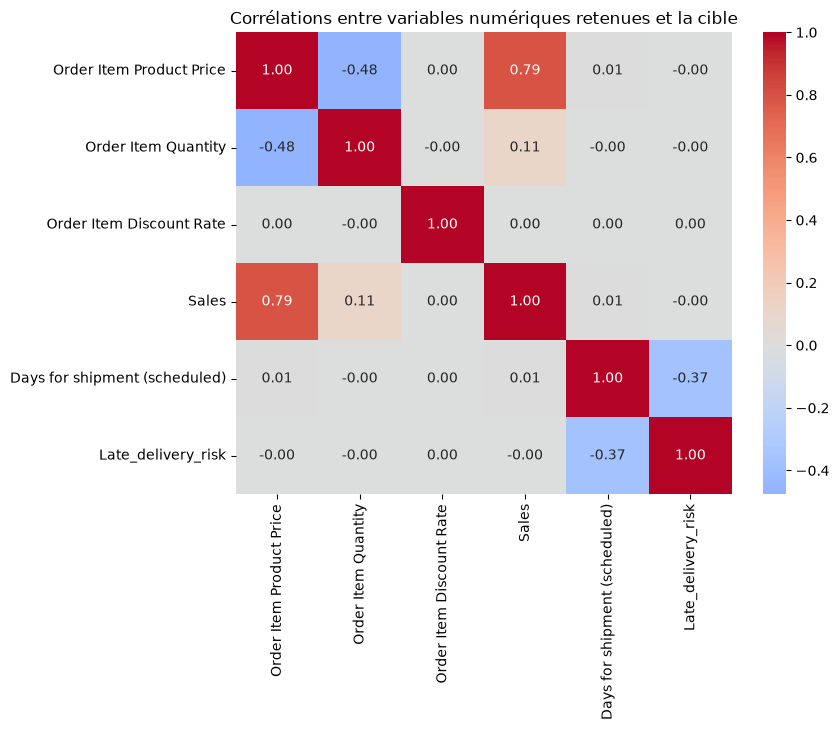

In [70]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_modelisation.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations entre variables numériques retenues et la cible")
plt.show()

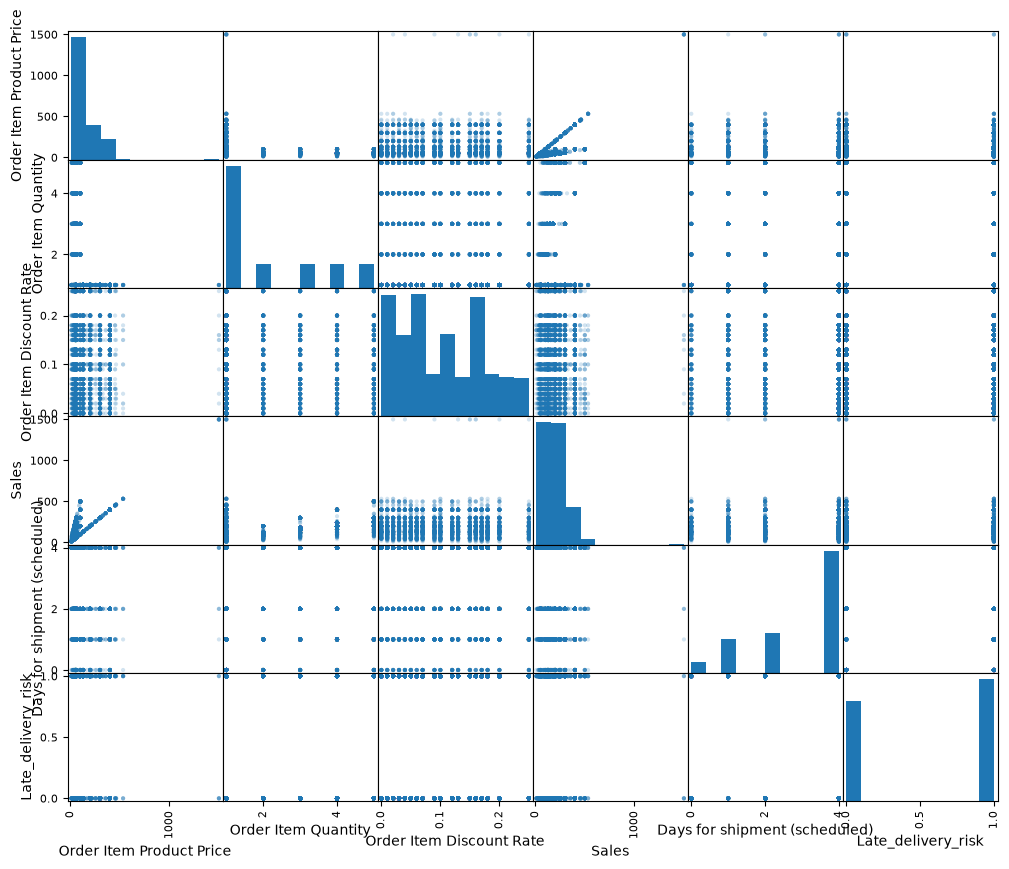

In [71]:
echantillon_sm = df_modelisation.sample(min(5000, len(df_modelisation)), random_state=42)
scatter_matrix(echantillon_sm[num_cols + ["Late_delivery_risk"]], figsize=(12, 10), alpha=0.2)
plt.show()

**Observations**: Entre variables retenues, la corrélation la plus forte est entre `Sales` et `Order Item Product Price` **0.79** : c'est attendu, le montant d'une ligne dépend du prix de l'article. Aucune variable numérique retenue n'est corrélée linéairement à la cible : le nuage de points ne montre aucune séparation des retards selon une variable numérique seule.

**Décision sur les entrées des pipelines**: Un seul jeu d'entrée pour tous les modèles : les 5 variables numériques standardisées et les variables catégorielles encodées en One-Hot, le tout dans un `ColumnTransformer` intégré au pipeline. On ne fait pas de pipelines avec des entrées différentes (par exemple réduites par ACP) : la section suivante montre que l'ACP n'apporte pas de réduction utile.

### 3.7. Réduction de dimension (ACP) PCA

[0.376 0.594 0.794 0.994 1.   ]


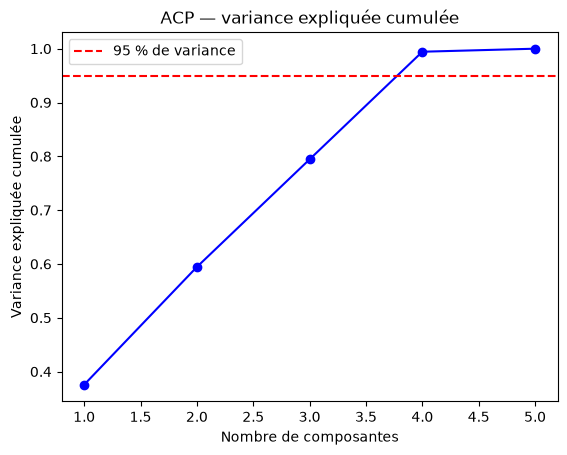

In [72]:
pca = PCA().fit(X_scaled)
variance_cumulee = np.cumsum(pca.explained_variance_ratio_)
print(variance_cumulee.round(3))

plt.plot(range(1, len(variance_cumulee) + 1), variance_cumulee, "bo-")
plt.axhline(y=0.95, color="r", linestyle="--", label="95 % de variance")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("ACP — variance expliquée cumulée")
plt.legend()
plt.show()

# Projection en 2D, utilisée pour visualiser les clusters plus bas
X_2d = PCA(n_components=2).fit_transform(X_scaled)

**Observations**: Il faut 4 composantes sur 5 pour dépasser 95 % de la variance (37,6 % → 59,4 % → 79,4 % → 99,4 %). Les variables portent donc chacune une information propre, et l'ACP ne réduit presque pas la dimension. La 5e composante n'explique que 0,6 % : une des variables est presque redondante avec les autres (`Sales` ≈ prix × quantité).

**Choix**: Pas d'ACP dans les pipelines supervisés : le gain (5 → 4 dimensions) est trop faible face à la perte d'interprétabilité. On utilise uniquement les 2 premières composantes (≈ 59 % de la variance) pour visualiser les données en 2D.

### 3.8. Clustering non supervisé et lien avec la cible

*On regroupe les lignes qui se ressemblent sans jamais montrer la cible à l'algorithme (K-Means, chapitre 6), puis on regarde si les groupes trouvés correspondent aux retards.*

#### 3.8.1.Choix du nombre de clusters k

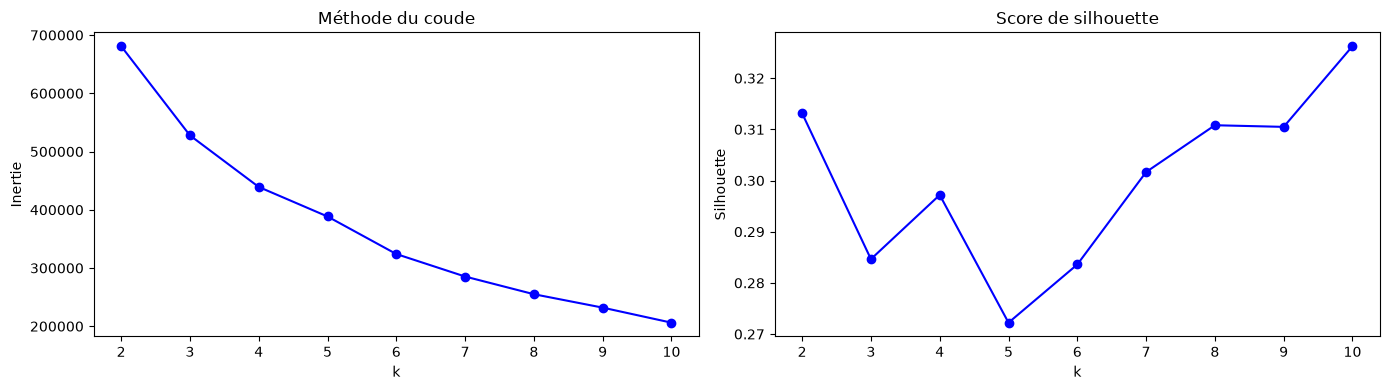

In [73]:
K = range(2, 11)
inerties, silhouettes = [], []
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_, sample_size=10000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(K, inerties, "bo-");    axes[0].set_title("Méthode du coude");   axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertie")
axes[1].plot(K, silhouettes, "bo-"); axes[1].set_title("Score de silhouette"); axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

**Observations**: La courbe du coude décroît régulièrement, sans cassure nette : elle ne permet pas de trancher (le cours précise que cette méthode est grossière). Le score de silhouette est le plus élevé à k = 2 (≈ 0,31) parmi les valeurs interprétables, puis remonte vers k = 9-10 : c'est un effet de fragmentation en petits groupes, pas une vraie structure. Les scores restent bas (< 0,35) : les données ne forment pas de groupes bien séparés.

**Choix** : k = 2, le meilleur score parmi les solutions interprétables.

In [74]:
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X_scaled)

profil = df.groupby("cluster")[num_cols + ["Late_delivery_risk"]].mean().round(3)
profil["taille"] = df["cluster"].value_counts().sort_index()
profil

,Order Item Product Price,Order Item Quantity,Order Item Discount Rate,Sales,Days for shipment (scheduled),Late_delivery_risk,taille
cluster,,,,,,,
0,84.096,2.406,0.102,162.090,2.929,0.548,144750
1,372.471,1.000,0.102,372.471,2.944,0.549,35758


In [75]:
# Tableau croisé cluster x cible (en % par cluster)
pd.crosstab(df["cluster"], df["Late_delivery_risk"], normalize="index").round(3) * 100

Late_delivery_risk,0,1
cluster,,
0,45.2,54.8
1,45.1,54.9


#### 3.8.2. Classes réelles et clusters : comparaison visuelle

*Comme dans le cours (classification à gauche, clustering à droite), on trace le même nuage de points deux fois : coloré par la vraie cible, puis par les clusters.*

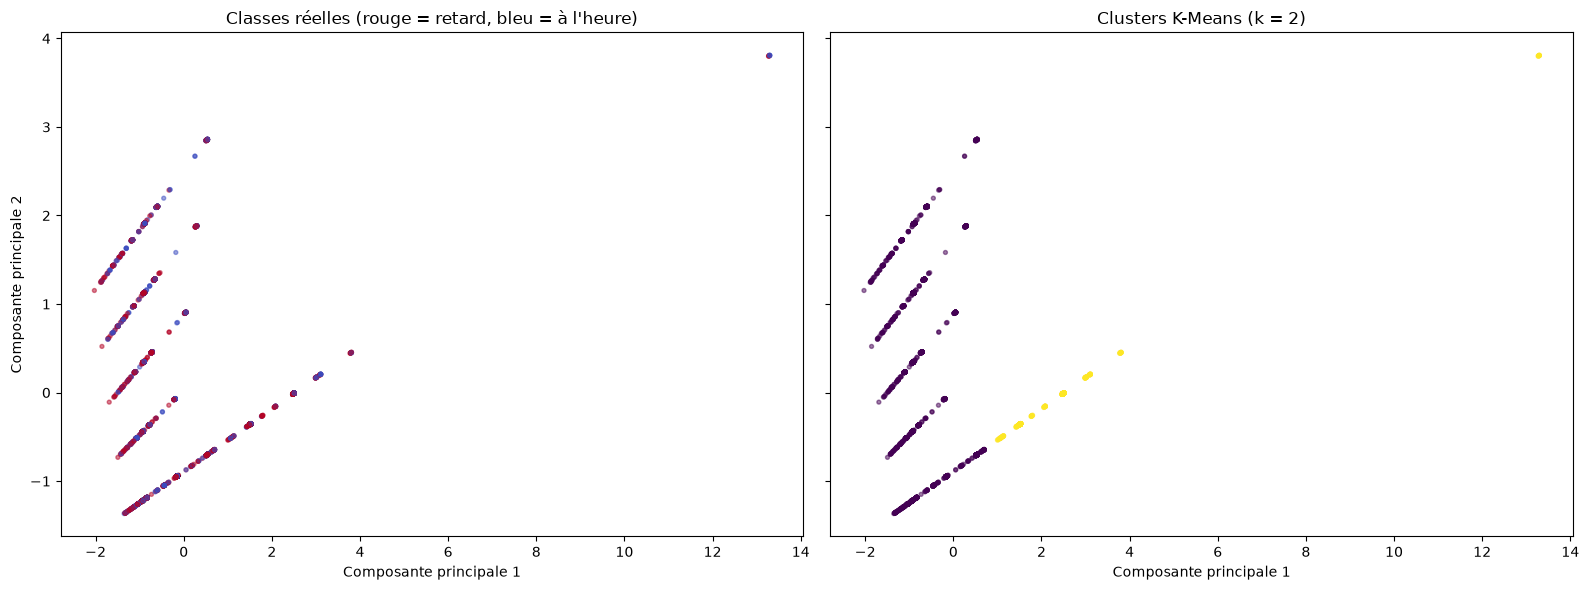

In [76]:
rng = np.random.RandomState(42)
positions = rng.choice(len(df), size=min(5000, len(df)), replace=False)   # 5 000 points pour la lisibilité

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
axes[0].scatter(X_2d[positions, 0], X_2d[positions, 1],
                c=df["Late_delivery_risk"].values[positions], cmap="coolwarm", s=8, alpha=0.5)
axes[0].set_title("Classes réelles (rouge = retard, bleu = à l'heure)")
axes[1].scatter(X_2d[positions, 0], X_2d[positions, 1],
                c=df["cluster"].values[positions], cmap="viridis", s=8, alpha=0.5)
axes[1].set_title("Clusters K-Means (k = 2)")
for ax in axes:
    ax.set_xlabel("Composante principale 1")
axes[0].set_ylabel("Composante principale 2")
plt.tight_layout()
plt.show()

**Observations**
* Les 2 clusters se distinguent par le prix et la quantité : le cluster 0 (144 750 lignes, 80 %) regroupe des articles à prix modéré (~84) achetés en plusieurs exemplaires, le cluster 1 (35 758 lignes, 20 %) des articles chers (~372) achetés à l'unité. Remise et délai annoncé sont identiques dans les deux.
* Le taux de retard est le même dans les deux clusters (54,82 % contre 54,87 %).
* Sur le graphique de gauche, les retards et les livraisons à l'heure sont mélangés partout : aucune zone du nuage n'est dominée par une classe. À droite, K-Means découpe le nuage selon le prix, ce qui n'a rien à voir avec la cible.

**Conclusion**: Le profil prix/quantité/remise d'une commande n'explique pas le retard, et ces 5 variables numériques ne suffisent pas à séparer les classes. Cela renforce l'hypothèse que le retard dépend surtout de facteurs logistiques (mode d'expédition, délai promis) et justifie d'inclure les variables catégorielles dans les modèles supervisés.

## 3.9 Synthèse de l'EDA : interprétations, hypothèses et conclusions

**Données**: 180 519 lignes × 53 colonnes, une ligne = un article commandé (65 741 commandes). Après nettoyage : 180 508 lignes, aucune valeur manquante. Les valeurs extrêmes (montants élevés, pertes) sont réelles et conservées. Plusieurs colonnes sont des doublons, des identifiants ou des données personnelles.

**Cible**: 54,8 % de retards contre 45,2 % : déséquilibre léger, pas de rééquilibrage, découpage stratifié et groupé par commande, suivi de la précision, du rappel et du F1 en plus de l'accuracy. Référence à battre : 54,8 % d'accuracy (toujours prédire « retard »).

**Fuites de données**: Le délai réel, le statut de livraison, la date d'expédition, le statut de commande et les bénéfices ne sont connus qu'après la livraison. Ils sont exclus : sans cela, un modèle afficherait un score quasi parfait mais inutilisable en pratique.

**Hypothèses testées.**
1. *Les variables numériques (prix, quantité, remise) expliquent le retard* → rejetée : corrélations quasi nulles et clusters avec le même taux de retard.
2. *La localisation du client explique le retard* → rejetée : sur 338 lieux, la dispersion du taux de retard (écart-type 8,8 points) est du même ordre que la fluctuation due au hasard.
3. *Le mode d'expédition et le délai promis expliquent le retard* → confirmée en exploration : de 38,1 % (Standard Class) à 95,3 % (First Class) de retards. Une règle sur le seul mode donne déjà environ 69,5 % de bonnes prédictions. C'est l'hypothèse principale à confirmer par les modèles, qui devront faire mieux que cette règle.

**Données d'entrée retenues pour la modélisation** : 5 variables numériques standardisées et les variables catégorielles à 100 modalités au plus, encodées en One-Hot, dans un pipeline unique ajusté sur le jeu d'entraînement.